# Inspecting a collected FindGoal dataset

What `mains/collect_world.py` writes, looked at: the layouts and where each episode starts, an episode from above
and through the agents' eyes, the episode lengths per behaviour, and the trajectories the ray tracing will read.

By default this collects a small dataset first (4 layouts × 3 episodes, as `tests/test_collect_world.py` does) into
`tests/output/collect_world`. To look at a real collection instead, set `DATA` to its `out_dir`.

In [12]:
import sys
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == 'tests' else Path.cwd()
sys.path[:0] = [str(ROOT / 'tests'), str(ROOT / 'mains')]
import collect_world as cw
import test_collect_world as t

DATA = None                                   # a collection's out_dir; None: a small one, collected here
if DATA is None:
    DATA = ROOT / 'tests' / 'output' / 'collect_world'
    cfg = t.small_collection(DATA) if not (DATA / 'dataset.h5').exists() else t.config(DATA)
else:
    DATA = Path(DATA)
    cfg = t.config(DATA)
print(DATA)

/home/ahmed/Ahmed-home/1- Projects/Research/Journal 2/code/c3jepa-wm/tests/output/collect_world


## What is in it

One row per step and per agent (the first row of an episode is its reset). `layout` is the reset seed of the walls,
`seed` the episode's own, `behaviour` the `MixedPolicy` behaviour of the episode (-1 at the reset).

In [14]:
f = h5py.File(DATA / 'dataset.h5', 'r')
offsets, lengths = f['ep_offset'][:], f['ep_len'][:]
print(f'{len(lengths)} episodes, {lengths.sum()} rows, {len(set(f["layout"][:, 0]))} layouts')
for k, d in f.items():
    if k not in ('ep_len', 'ep_offset'):
        print(f'  {k:14s} {str(d.shape):26s} {d.dtype}')
print(dict(f.attrs))

def episode(k, columns=None):
    "Episode k's rows, as arrays."
    rows = slice(int(offsets[k]), int(offsets[k] + lengths[k]))
    return {c: f[c][rows] for c in (columns or [c for c in f if c not in ('ep_len', 'ep_offset')])}

12 episodes, 668 rows, 4 layouts
  action         (668, 2)                   float32
  behaviour      (668, 2)                   int64
  direction      (668, 2)                   int64
  goal           (668, 2, 224, 224, 3)      uint8
  goal_position  (668, 2, 2)                int64
  id             (668,)                     int64
  image          (668, 2, 7, 7, 3)          int64
  layout         (668, 2)                   int64
  mission        (668, 2)                   int64
  pixels         (668, 2, 224, 224, 3)      uint8
  position       (668, 2, 2)                int64
  reward         (668, 2)                   float32
  seed           (668,)                     int64
  state          (668, 15, 15, 3)           int64
  step_idx       (668,)                     int64
  terminated     (668, 2)                   bool
  truncated      (668, 2)                   bool
{'env_kwargs': '{"agents": 2, "size": 15, "num_obstacles": 6, "n_clutter": 10, "max_steps": 150}', 'env_name': 'Mul

## Episode lengths per behaviour

An episode ends when both agents are on the goal, or after `max_steps`. Random episodes run to the limit; the
goal-directed ones are short.

                 episodes  steps: mean  median  reached
random                  3        150.0     150       0%
epsilon_expert          7         20.0      20     100%
waypoint                2         33.0      33     100%


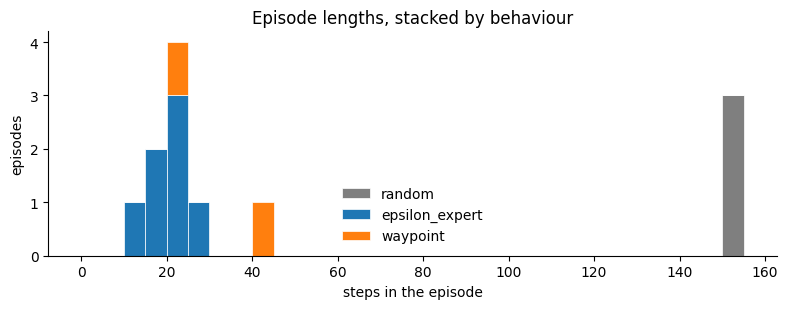

In [15]:
NAMES = cw.BEHAVIOURS
COLORS = {'random': '#7f7f7f', 'epsilon_expert': '#1f77b4', 'waypoint': '#ff7f0e'}   # fixed per behaviour
behaviour = np.array([f['behaviour'][o:o + n, 0].max() for o, n in zip(offsets, lengths)])
reached = np.array([f['terminated'][o + n - 1].all() for o, n in zip(offsets, lengths)])
steps = lengths - 1

print(f"{'':15s} {'episodes':>9s} {'steps: mean':>12s} {'median':>7s} {'reached':>8s}")
for b, name in enumerate(NAMES):
    s = steps[behaviour == b]
    if len(s):
        print(f'{name:15s} {len(s):9d} {s.mean():12.1f} {np.median(s):7.0f} {reached[behaviour == b].mean():8.0%}')

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.arange(0, cfg.env.max_steps + 6, 5)
ax.hist([steps[behaviour == b] for b in range(len(NAMES))], bins=bins, stacked=True,
        color=[COLORS[n] for n in NAMES], label=NAMES, edgecolor='white', linewidth=0.5)
ax.set(xlabel='steps in the episode', ylabel='episodes', title='Episode lengths, stacked by behaviour')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()

## The layouts, and where their episodes start

One panel per layout (its walls in grey, from the dataset's `state`). Each episode of the layout has its own goal
(star) and starts (circles: agent 0 red, agent 1 blue), drawn in the episode's colour: same walls, different
goals and starts.

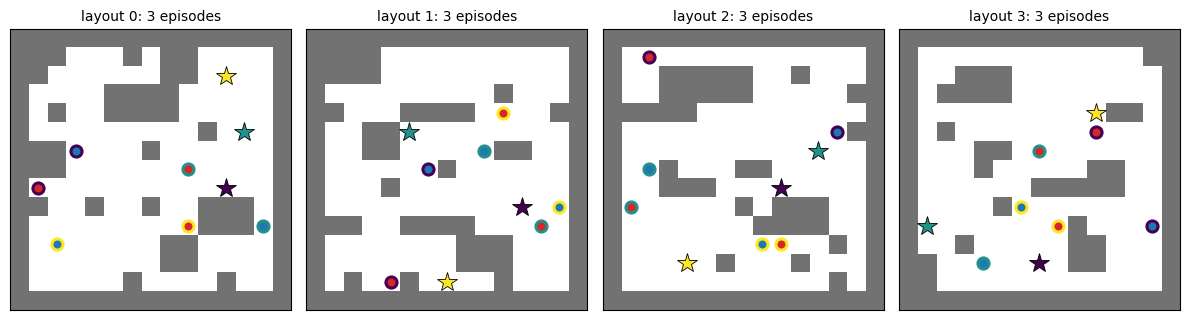

In [16]:
from stable_marl.envs.multigrid.core.constants import Type
from stable_marl.envs.multigrid.core.world_object import WorldObj

def walls(state):
    return state[..., WorldObj.TYPE] == Type.wall.to_index()

def draw_walls(ax, state):
    ax.imshow(walls(state).T, cmap='Greys', vmin=0, vmax=1.6, origin='upper')   # [x, y] -> image rows y
    ax.set(xticks=[], yticks=[])

AGENT = ['#d62728', '#1f77b4']                # the env's agent colours: red, blue (the goal is green)
layout_of = f['layout'][:, 0][offsets]
shown = sorted(set(layout_of))[:8]
fig, axes = plt.subplots(1, len(shown), figsize=(3 * len(shown), 3.3), squeeze=False)
for ax, layout in zip(axes[0], shown):
    ks = np.flatnonzero(layout_of == layout)
    draw_walls(ax, f['state'][offsets[ks[0]]])
    for c, k in enumerate(ks):
        e = episode(k, ['position', 'goal_position'])
        shade = plt.cm.viridis(c / max(len(ks) - 1, 1))
        gx, gy = e['goal_position'][0, 0]
        ax.plot(gx, gy, '*', ms=15, color=shade, mec='k', mew=0.6)
        for i in range(2):
            ax.plot(*e['position'][0, i], 'o', ms=8, color=AGENT[i], mec=shade, mew=2.2)
    ax.set_title(f'layout {layout}: {len(ks)} episodes', fontsize=10)
plt.tight_layout()

In [17]:
# the same walls in every episode of a layout, and as the ray tracing builds them (reset with the layout's seed)
for layout in shown:
    ks = np.flatnonzero(layout_of == layout)
    ref = t.reference_walls(cfg, layout)
    same = [np.array_equal(walls(f['state'][offsets[k]]), ref) for k in ks]
    print(f'layout {layout}: walls as traced in {sum(same)} / {len(ks)} episodes')

layout 0: walls as traced in 3 / 3 episodes
layout 1: walls as traced in 3 / 3 episodes
layout 2: walls as traced in 3 / 3 episodes
layout 3: walls as traced in 3 / 3 episodes


## One episode from above

The env rendered at the reset (rebuilt from the episode's seed, through the same `LayoutWrapper`), and the agents'
paths over the walls. Change `K` to look at another episode.

episode 4: layout 0, behaviour waypoint, 43 steps, both on the goal: True


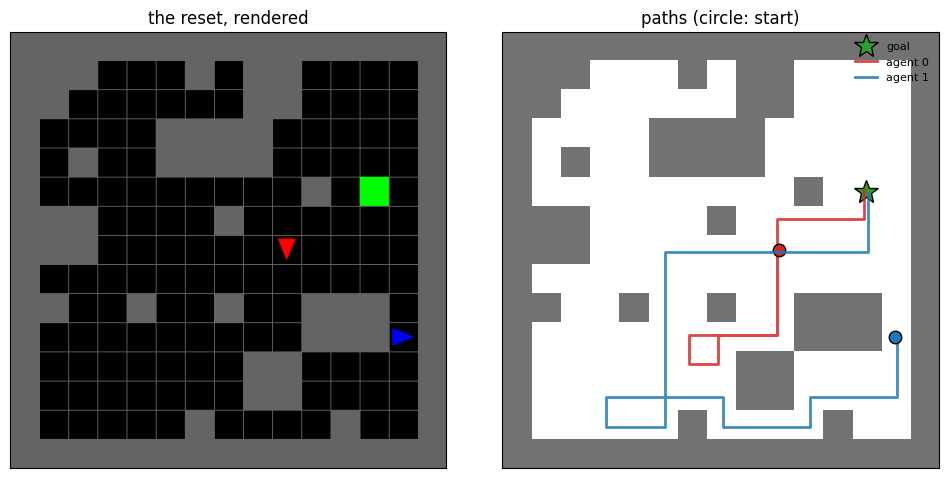

In [27]:
import gymnasium as gym
import stable_marl.envs  # noqa: F401

K = next((int(np.argmax(behaviour == NAMES.index(n))) for n in ('waypoint', 'epsilon_expert') if (behaviour == NAMES.index(n)).any()), 0)
e = episode(K)
print(f"episode {K}: layout {e['layout'][0, 0]}, behaviour {NAMES[e['behaviour'][1, 0]]}, {len(e['seed']) - 1} steps, "
      f"both on the goal: {bool(e['terminated'][-1].all())}")

env = cw.LayoutWrapper(gym.make(cfg.env_id, render_mode='rgb_array', **cw._env_kwargs(cfg)), list(range(*cfg.layouts)), variations=cw._variations(cfg))
obs, _ = env.reset(seed=int(e['seed'][0]))
assert np.array_equal(np.array([obs[i]['position'] for i in range(2)]), e['position'][0])   # the same reset

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
axes[0].imshow(env.unwrapped.get_frame(highlight=False))
axes[0].set(title='the reset, rendered', xticks=[], yticks=[])
draw_walls(axes[1], e['state'][0])
gx, gy = e['goal_position'][0, 0]
axes[1].plot(gx, gy, '*', ms=18, color='#2ca02c', mec='k', label='goal')
for i in range(2):
    p = e['position'][:, i]
    jitter = (i - 0.5) * 0.15                  # the two paths side by side where they overlap
    axes[1].plot(p[:, 0] + jitter, p[:, 1] + jitter, '-', lw=2, color=AGENT[i], alpha=0.85, label=f'agent {i}')
    axes[1].plot(*p[0], 'o', ms=9, color=AGENT[i], mec='k')
axes[1].set_title('paths (circle: start)')
axes[1].legend(frameon=False, loc='upper right', fontsize=8)
plt.tight_layout()

## Through the agents' eyes

`pixels`: each agent's 7 × 7 view (what the world model sees), at a few steps of the episode, and `goal`: the view
from the goal cell (constant over the episode).

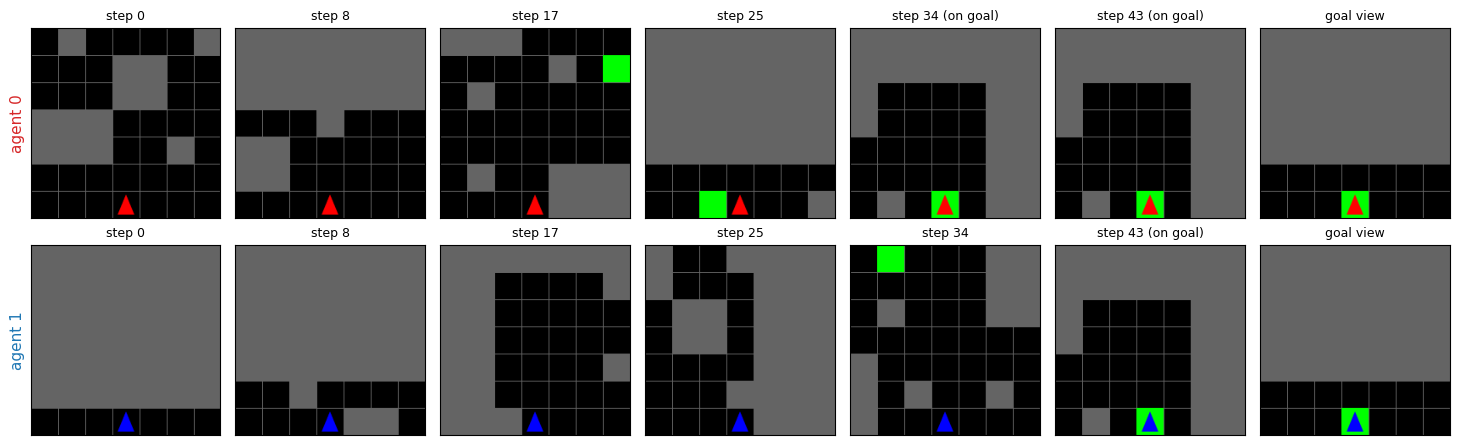

In [28]:
T = len(e['pixels'])
ts = np.unique(np.linspace(0, T - 1, 6).astype(int))
fig, axes = plt.subplots(2, len(ts) + 1, figsize=(2.1 * (len(ts) + 1), 4.6))
for i in range(2):
    for c, step in enumerate(ts):
        axes[i, c].imshow(e['pixels'][step, i])
        axes[i, c].set(xticks=[], yticks=[])
        done = ' (on goal)' if e['terminated'][step, i] else ''
        axes[i, c].set_title(f'step {step}{done}', fontsize=9)
    axes[i, -1].imshow(e['goal'][0, i])
    axes[i, -1].set(xticks=[], yticks=[])
    axes[i, -1].set_title('goal view', fontsize=9)
    axes[i, 0].set_ylabel(f'agent {i}', color=AGENT[i], fontsize=11)
plt.tight_layout()

## The trajectories the ray tracing reads

`trajectories/trajectories_<layout>.npz` holds every agent's cell at every step (−1 once it is on the goal, or after
the episode). The pairs of cells the two agents were in at the same step are what gets traced. Here, the cells a
layout's episodes visited (darker: more often; white: never), and the number of pairs to trace.

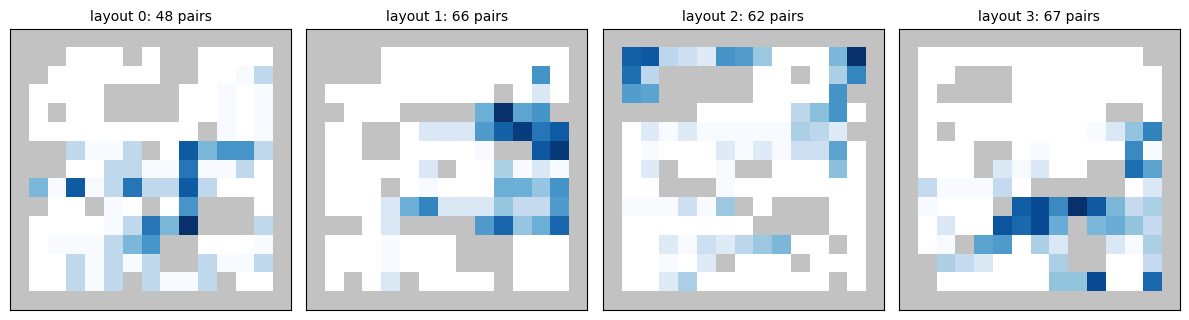

In [29]:
from c3jepa_wm.comm.channel_data import visited_pairs

fig, axes = plt.subplots(1, len(shown), figsize=(3 * len(shown), 3.3), squeeze=False)
for ax, layout in zip(axes[0], shown):
    z = np.load(DATA / 'trajectories' / f'trajectories_{layout}.npz')
    cells = z['cells'].reshape(-1, 2)
    cells = cells[cells[:, 0] >= 0]
    visits = np.zeros(walls(f['state'][0]).shape)
    np.add.at(visits, (cells[:, 0], cells[:, 1]), 1)
    ks = np.flatnonzero(layout_of == layout)
    wall = walls(f['state'][offsets[ks[0]]])
    img = np.where(wall | (visits == 0), np.nan, np.log1p(visits))   # white: never visited
    ax.imshow(np.where(wall, 0.35, np.nan).T, cmap='Greys', vmin=0, vmax=1)
    ax.imshow(img.T, cmap='Blues')
    ax.set(xticks=[], yticks=[])
    pairs = visited_pairs(DATA / 'trajectories' / f'trajectories_{layout}.npz')
    ax.set_title(f'layout {layout}: {len(pairs)} pairs', fontsize=10)
plt.tight_layout()

In [30]:
f.close()
env.close()